***Week 8 Jupyter Notebook — Assignment Instructions***

Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.

For this week, include ideas such as K-Nearest Neighbors and distance metrics. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday.

In Week 12, compile findings from the weekly notebooks into Milestone Two. The referenced rubric/link was not provided; this notebook addresses the supplied weekly instructions. The saved notebook is prepared for local review; submission is a separate course-system action.

# Week 8: K-Nearest Neighbors and distance metrics

Calvin Baker · DX799 Integrated Capstone · Three independent dataset analyses

## tl;dr

- **Loan_Default.csv** — recorded Status 1: **Euclidean KNN**, test AUC **0.609**, AP **0.334**, F1 at the validation cutoff **0.399**, test n=2,400.
- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Euclidean KNN**, test AUC **0.620**, AP **0.210**, F1 at the validation cutoff **0.272**, test n=2,400.
- **bank_customers.csv** — checking account versus savings/CD: **Manhattan KNN**, test AUC **0.333**, AP **0.788**, F1 at the validation cutoff **0.444**, test n=8.

Large neighborhoods were preferred on both loan samples, but KNN did not consistently improve on logistic regression. The scaling experiment helped one loan dataset and hurt the other. The bank study uses only 39 eligible rows and is a methods demonstration.

**Delivered run:** 34 code cells executed from a fresh kernel with 21 saved figures. These static summaries describe the saved run; revise them after changing inputs or settings.

## Context & Methods

**Question:** Does a local neighborhood improve classification, and how do distance, scaling, k and vote weighting affect the answer?

Minkowski distance is $d_p(x,z)=(\sum_j |x_j-z_j|^p)^{1/p}$. Manhattan distance uses $p=1$; Euclidean uses $p=2$. Uniform voting averages neighboring labels; distance voting gives nearer profiles greater influence (exact matches receive special treatment). Larger k smooths predictions but can erase local structure; small k can memorize noise.

Numeric features receive training-fold median imputation and standardization. Categorical fields receive training-fold mode imputation and **full** one-hot encoding. Matching versus differing categories contributes 0 versus 2 to squared Euclidean distance (or 0 versus 2 to Manhattan distance) per complete category block. Numeric versus categorical weighting remains a modeling choice; unknown categories map to all-zero blocks and may have different geometry. No ordinal category codes are used.

### Key Assumptions and evaluation plan

- Each CSV is an independent source; there are no joins between unrelated people or loans. The source paths are `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv`, and `DATA/bank_customers.csv`.
- Continue Week 4's classification targets and conservative predictor sets. For matched weekly experiments, take **12,000 uniformly sampled rows** per loan dataset (or all rows if fewer). Weeks 8 and 9 use the same loading, sampling and split code as Weeks 5–6. This differs from Week 4's full Loan_Default population and 24,000-row LendingClub sample; do **not** attribute cross-week score changes solely to algorithms.
- Loans use a seed-42, stratified 60% train / 20% validation / 20% test split. Bank records use Week 4's account-group split and three-fold group CV. No account crosses partitions or CV folds. Loan IDs identify rows, not verified unique borrowers; random splits assume sufficient row independence.
- Training-only three-fold CV chooses parameters by mean **ROC AUC**. Validation AUC chooses the distance family. AP and fold variation are shown for context. In a tie, the first listed family wins. Finite grids may select an edge; search ranges would need expansion inside training for further optimization.
- Select the F1 cutoff only on validation. Freeze the training-fitted model and cutoff, then evaluate on test once. **No development-set refit** is performed, preserving the score scale used for threshold selection. Prespecified models and fixed-C logistic baselines are also shown on test, without choosing another winner afterward.
- Accuracy alone is misleading with imbalance. Report AUC, AP, prevalence, precision, recall, F1, balanced accuracy, predicted-positive counts and exact confusion counts. A prior-probability/majority baseline has AUC 0.5 and AP equal to prevalence. AUC measures ranking; a high AUC does not guarantee useful decisions or calibrated probabilities.
- The bank reference date remains **2026-09-26** for comparability with prior weeks; it is not today's date. It yields 39 eligible records. Exclusion reasons can overlap. Bank estimates demonstrate methods and are too small for reliable population conclusions.
- Original CSVs stay unchanged. Use the repository's `requirements-notebooks.txt`, then **Restart Kernel → Run All**. Each notebook is self-contained and prints the environment versions; no hidden fitted artifacts are required.

### 1. Set up the environment

Use `requirements-notebooks.txt`; run from the repository or its parent workspace. Seeds and bounded numerical threads make the workflow reproducible.

In [1]:
from pathlib import Path
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

# A fixed seed and bounded numerical threads make the workflow repeatable.
SEED = 42
thread_limit = threadpool_limits(limits=1)
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 115,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'axes.axisbelow': True})
BLUE, ORANGE, GRAY = '#245E91', '#B96520', '#50545A'

# Support opening from the repository itself or its parent workspace.
data_candidates = [Path.cwd() / 'DATA',
                   Path.cwd() / 'Data-Science-Capstone-DX799' / 'DATA']
DATA_DIR = next((p for p in data_candidates if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Open this notebook from the repository or its parent; DATA is required.')
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'NumPy': np.__version__, 'scikit-learn': sklearn.__version__,
                   'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
import time
SAMPLE_SIZE = 12_000
results = []
from sklearn.metrics import log_loss, brier_score_loss

Python          3.13.5
pandas           3.0.0
NumPy            2.4.1
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared, unfitted tools

All preprocessing is refitted inside each training fold. Each dataset has independent fitted models.

In [2]:
def extra_split(X, y, groups=None, classification=False):
    """Use a row split for loans and account-group separation for bank records."""
    if groups is None:
        development, test = train_test_split(np.arange(len(X)), test_size=0.20,
            random_state=SEED, stratify=y if classification else None)
        train, valid = train_test_split(development, test_size=0.25, random_state=SEED,
            stratify=y.iloc[development] if classification else None)
        cv = (StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
              if classification else KFold(n_splits=3, shuffle=True, random_state=SEED))
        folds = list(cv.split(X.iloc[train], y.iloc[train]))
    else:
        development, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
            random_state=SEED).split(X, y, groups))
        train_local, valid_local = next(GroupShuffleSplit(n_splits=1, test_size=0.25,
            random_state=SEED).split(X.iloc[development], y.iloc[development], groups.iloc[development]))
        train, valid = development[train_local], development[valid_local]
        # Do not split records from the same account across CV folds either.
        folds = list(GroupKFold(n_splits=3).split(X.iloc[train], y.iloc[train], groups.iloc[train]))
        sets = [set(groups.iloc[index]) for index in [train, valid, test]]
        assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
    assert len(set(train) | set(valid) | set(test)) == len(X)
    if classification:
        for index in [train, valid, test]:
            assert y.iloc[index].nunique() == 2, 'Both classes are required in every evaluation split.'
        for fit, holdout in folds:
            assert y.iloc[train].iloc[fit].nunique() == 2
            assert y.iloc[train].iloc[holdout].nunique() == 2
    return train, valid, test, development, folds


def prepare(numeric, categorical, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    transformers = [('numeric', Pipeline(steps), numeric)]
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

def pipeline(model, scale=True):
    return Pipeline([('prepare', prepare(numeric, categorical, scale)), ('model', model)])

def score_values(model, data):
    return model.predict_proba(data)[:, 1]

def metrics(actual, scores, prediction):
    return {'ROC AUC': roc_auc_score(actual, scores),
            'Average precision': average_precision_score(actual, scores),
            'Accuracy': accuracy_score(actual, prediction),
            'Balanced accuracy': balanced_accuracy_score(actual, prediction),
            'Precision': precision_score(actual, prediction, zero_division=0),
            'Recall': recall_score(actual, prediction, zero_division=0),
            'F1': f1_score(actual, prediction, zero_division=0),
            'Predicted positive': int(np.sum(prediction))}

def tune(model, grid, scale=True):
    search = GridSearchCV(pipeline(model, scale), grid, cv=folds,
        scoring={'auc':'roc_auc','ap':'average_precision'}, refit='auc',
        n_jobs=1, return_train_score=True, error_score='raise')
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    estimator = search.best_estimator_
    row = {'CV AUC': search.best_score_,
           'CV AUC SD': search.cv_results_['std_test_auc'][search.best_index_],
           'Train AUC': roc_auc_score(y_train, score_values(estimator, X_train)),
           'Validation AUC': roc_auc_score(y_valid, score_values(estimator, X_valid)),
           'Validation AP': average_precision_score(y_valid, score_values(estimator, X_valid)),
           'Fit seconds': elapsed, 'Parameters': search.best_params_}
    return search, row

## Data and Results

## A. Loan_Default.csv — independent analysis

**Outcome:** recorded `Status=1` versus 0, with all valid statuses eligible before uniform sampling. Use loan amount, income, credit score, term, loan type, purpose and occupancy. Exclude identifiers, sensitive demographic fields, pricing, property/LTV/DTI fields and credit_type because the prior leakage audit found status-linked artifacts. Missingness in included fields can still carry collection artifacts; removing the worst fields does not prove leakage-free future prediction. The observation window/status semantics are not documented in the supplied files.

### A1. Load and reconcile source data

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,5497,1703,0.2365,7200
Validation,2400,1832,568,0.2367,2400
Test,2400,1832,568,0.2367,2400


,Training missing (%)
loan_amount,0.0000
income,6.6667
Credit_Score,0.0000
term,0.0000
loan_type,0.0000
loan_purpose,0.0833
occupancy_type,0.0000


,loan_amount,income,Credit_Score,term
min,"36,500.0000",0.0000,500.0000,96.0000
median,"306,500.0000","5,820.0000",700.0000,360.0000
max,"3,006,500.0000","146,520.0000",900.0000,360.0000


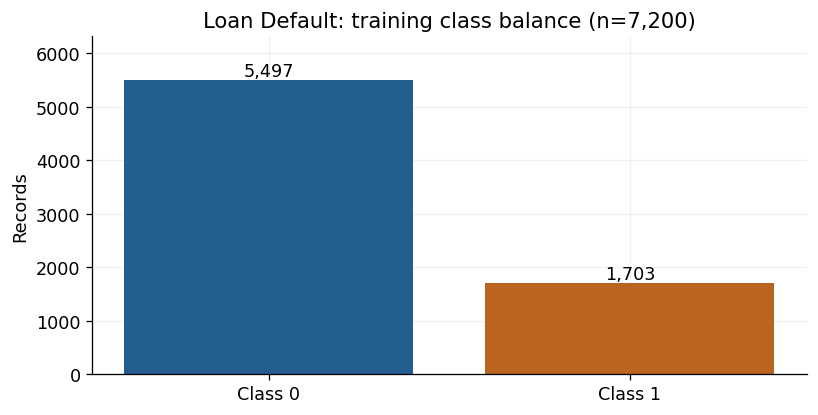

In [4]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### Audit status-linked missingness

The following training-only check demonstrates why seemingly predictive fields are excluded. It is not a candidate model.

In [5]:
audit_fields=['rate_of_interest','Interest_rate_spread','Upfront_charges','property_value','LTV','dtir1']
training_source=source_frame.loc[X_train.index]
audit=training_source.groupby('Status')[audit_fields].agg(lambda s:s.isna().mean()).T
audit.columns=['Missing share, class 0','Missing share, class 1']
display(audit)
artifact_accuracy=accuracy_score(y_train,training_source['rate_of_interest'].isna().astype(int))
display(Markdown(f'**Training-only audit:** the missing-interest-rate rule has {artifact_accuracy:.2%} accuracy. '
    'Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. '
    'This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.'))

,"Missing share, class 0","Missing share, class 1"
rate_of_interest,0.0000,0.9941
Interest_rate_spread,0.0000,1.0000
Upfront_charges,0.0331,0.9953
property_value,0.0000,0.4116
LTV,0.0000,0.4116
dtir1,0.0773,0.4422


**Training-only audit:** the missing-interest-rate rule has 99.86% accuracy. Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.

### A3. Tune parameters inside training CV

In [6]:
# A compact grid is prespecified. Bank k must fit the smallest training fold.
k_values=[1,3,5,9] if groups is not None else [5,25,75,151]
assert max(k_values)<=min(len(a) for a,b in folds)
specifications={
    'Manhattan KNN':(KNeighborsClassifier(metric='minkowski',p=1,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']}),
    'Euclidean KNN':(KNeighborsClassifier(metric='minkowski',p=2,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=True)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:s.best_estimator_ for name,s in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,**s.best_params_} for name,s in searches.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. Training scores include each record itself among its neighbors; '
    'distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Manhattan KNN,0.6031,0.0046,0.6307,0.6202,0.3313,6.4837
Euclidean KNN,0.5969,0.0059,1.0000,0.6216,0.3228,3.6127


,Model,model__n_neighbors,model__weights
0,Manhattan KNN,151,uniform
1,Euclidean KNN,151,distance


Validation selected **Euclidean KNN**. Training scores include each record itself among its neighbors; distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.

### A4. Inspect distance, k and vote weighting

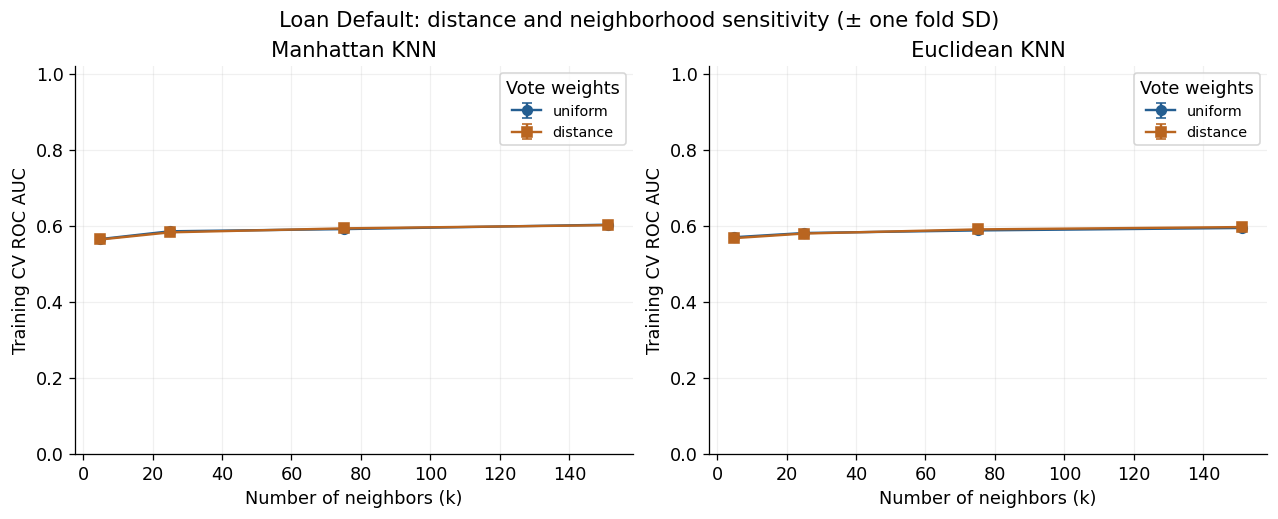

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout='constrained')
for ax,(name,search) in zip(axes,searches.items()):
    cv=pd.DataFrame(search.cv_results_)
    for weight,color,marker in [('uniform',BLUE,'o'),('distance',ORANGE,'s')]:
        part=cv[cv['param_model__weights'].eq(weight)].sort_values('param_model__n_neighbors')
        ax.errorbar(part['param_model__n_neighbors'].astype(int),part['mean_test_auc'],
            yerr=part['std_test_auc'],label=weight,color=color,marker=marker,capsize=3)
    ax.set(title=name,xlabel='Number of neighbors (k)',ylabel='Training CV ROC AUC',ylim=(0,1.02))
    ax.legend(title='Vote weights',fontsize=9)
fig.suptitle(f'{plot_label}: distance and neighborhood sensitivity (± one fold SD)')
plt.show()

### A5. Compare scaling with a fixed model

,Numeric scaling,Mean CV AUC,Fold SD,Fixed k
0,None,0.5611,0.0112,25
1,Standard,0.5812,0.0035,25


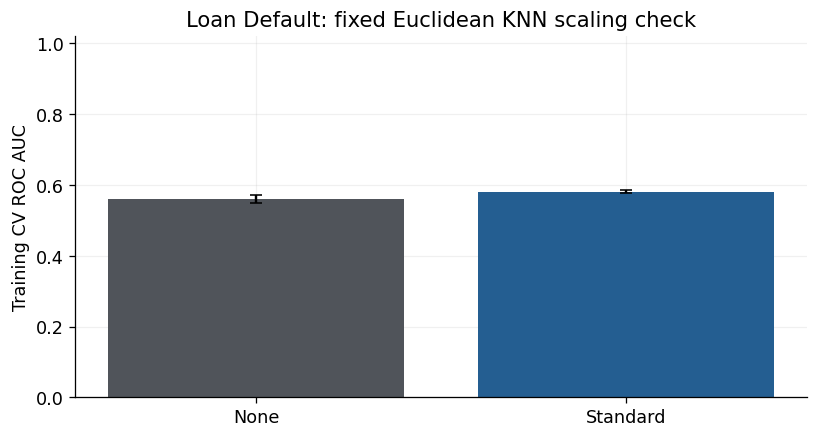

Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.

In [8]:
# Fixed k and equal votes isolate scaling; this does not replace the prespecified selection.
scale_k=5 if groups is not None else 25
scale_rows=[]
for scale in [False,True]:
    fixed=pipeline(KNeighborsClassifier(n_neighbors=scale_k,p=2,weights='uniform',algorithm='brute'),scale=scale)
    cv_scores=cross_val_score(fixed,X_train,y_train,cv=folds,scoring='roc_auc',n_jobs=1)
    scale_rows.append({'Numeric scaling':'Standard' if scale else 'None','Mean CV AUC':cv_scores.mean(),
        'Fold SD':cv_scores.std(ddof=0),'Fixed k':scale_k})
scale_table=pd.DataFrame(scale_rows)
display(scale_table)
fig,ax=plt.subplots(figsize=(7,3.7),layout='constrained')
ax.bar(scale_table['Numeric scaling'],scale_table['Mean CV AUC'],
    yerr=scale_table['Fold SD'],capsize=4,color=[GRAY,BLUE])
ax.set(ylim=(0,1.02),ylabel='Training CV ROC AUC',title=f'{plot_label}: fixed Euclidean KNN scaling check')
plt.show()
display(Markdown('Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, '
    'not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.'))

### A6. Inspect validation neighborhood distances

,Nearest distance,kth-neighbor distance,Nearest / kth
count,"2,400.0000","2,400.0000","2,400.0000"
mean,0.2433,1.2659,0.1757
min,0.0086,0.5510,0.0057
50%,0.1618,1.2287,0.1536
max,3.2321,13.4737,0.7643


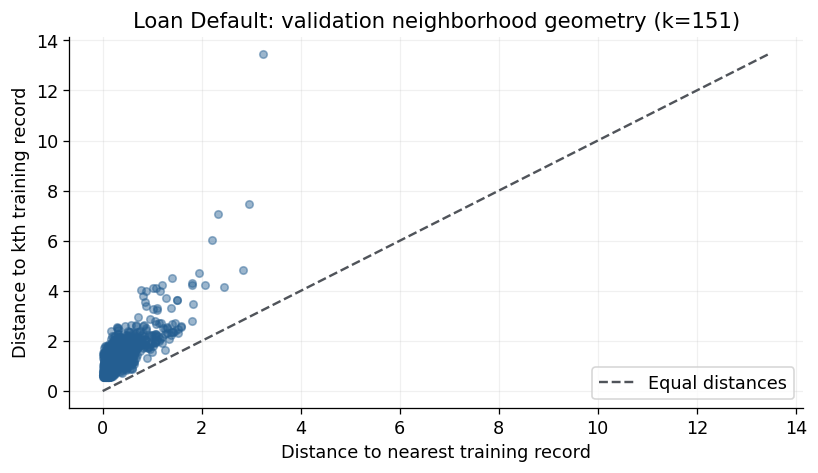

Transformed feature count: **14**. Median nearest/kth distance ratio: **0.154**; **0** validation rows have a zero-distance training neighbor. Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.

In [9]:
# Inspect validation-to-training distances without displaying customer or loan identifiers.
Z_valid=selected.named_steps['prepare'].transform(X_valid)
Z_train=selected.named_steps['prepare'].transform(X_train)
model=selected.named_steps['model']
distances,neighbors=model.kneighbors(Z_valid)
nearest=distances[:,0]; farthest=distances[:,-1]
ratio=np.divide(nearest,farthest,out=np.zeros_like(nearest),where=farthest>0)
display(pd.DataFrame({'Nearest distance':nearest,'kth-neighbor distance':farthest,
    'Nearest / kth':ratio}).describe().loc[['count','mean','min','50%','max']])
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.scatter(nearest,farthest,color=BLUE,alpha=.45,s=22,marker='o')
upper=max(float(farthest.max()),.01)
ax.plot([0,upper],[0,upper],color=GRAY,linestyle='--',label='Equal distances')
ax.set(xlabel='Distance to nearest training record',ylabel='Distance to kth training record',
    title=f'{plot_label}: validation neighborhood geometry (k={model.n_neighbors})')
ax.legend();plt.show()
display(Markdown(f'Transformed feature count: **{Z_train.shape[1]}**. Median nearest/kth distance ratio: '
    f'**{np.median(ratio):.3f}**; **{int((nearest==0).sum())}** validation rows have a zero-distance training neighbor. '
    'Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. '
    'Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6216,0.3228,0.7629,0.4997,0.0000,0.0000,0.0000,1
Validation F1,0.6216,0.3228,0.4867,0.5909,0.2872,0.7887,0.4211,1560


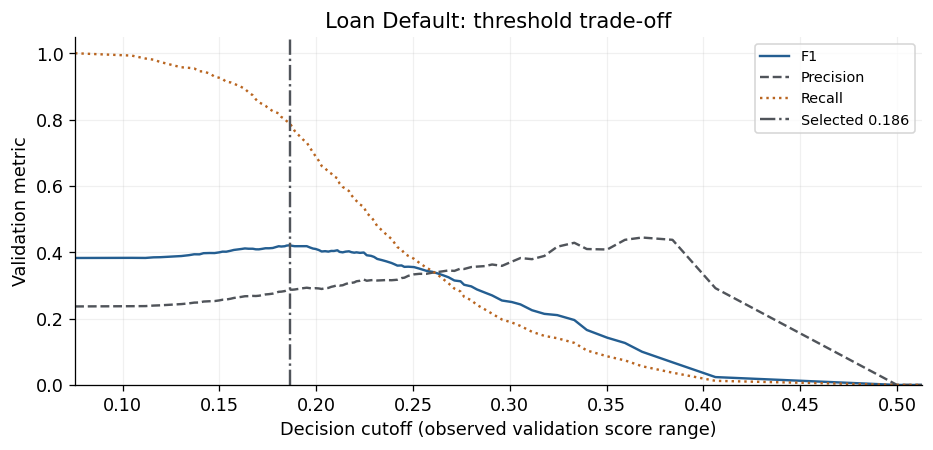

In [10]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [11]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Manhattan KNN,0.6117,0.3168,0.7633,0.5000,0.0000,0.0000,0.0000,0,0.5346,0.1762
Euclidean KNN,0.6092,0.3343,0.7633,0.5006,0.5000,0.0018,0.0035,2,0.5341,0.1758
Logistic baseline,0.5906,0.2968,0.7633,0.5000,0.0000,0.0000,0.0000,0,0.5421,0.1781
Prevalence baseline,0.5000,0.2367,0.7633,0.5000,0.0000,0.0000,0.0000,0,0.5472,0.1807
Euclidean KNN (validation F1 cutoff),0.6092,0.3343,0.4771,0.5658,0.2742,0.7342,0.3992,1521,0.5341,0.1758


95% stratified row-bootstrap AUC interval: [0.586, 0.639]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

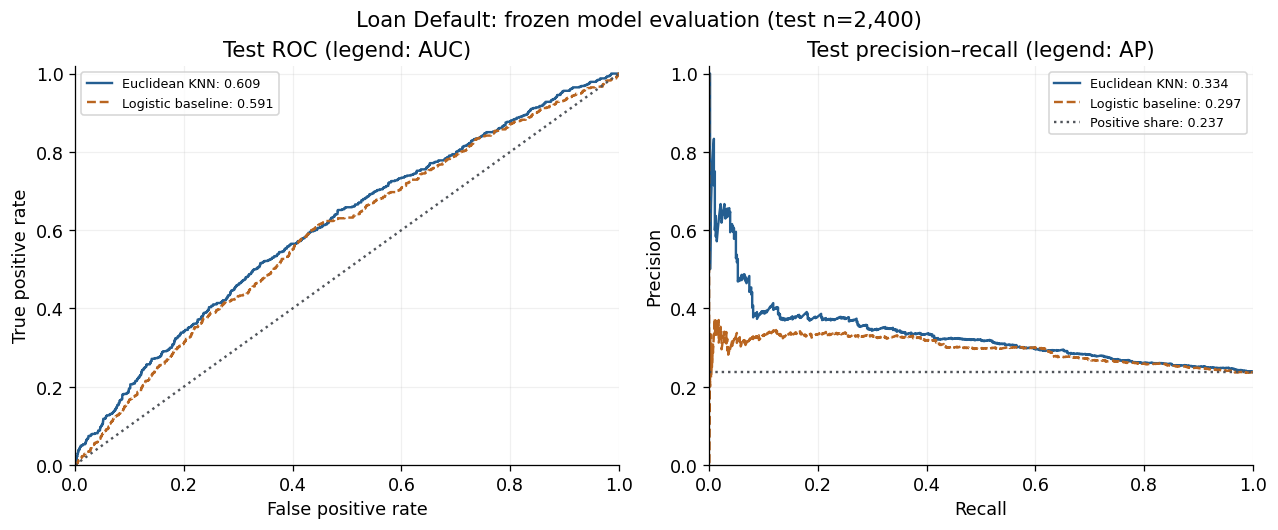

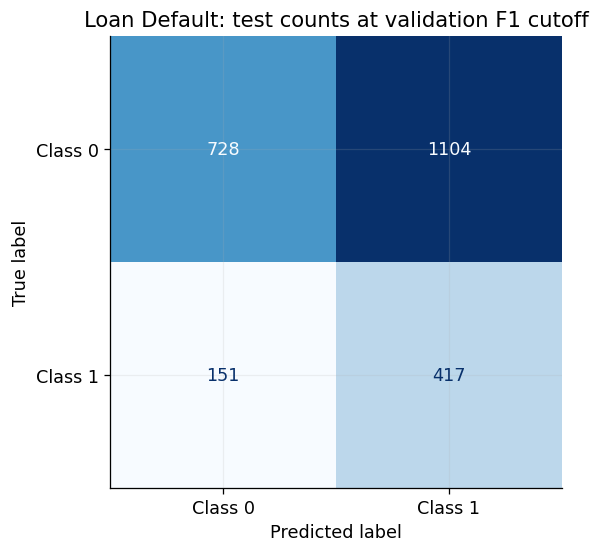

In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [13]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — Loan_Default.csv

The prespecified selection gives **Euclidean KNN**, with test ROC AUC **0.609** and average precision **0.334** against test positive share **0.237**. Logistic baseline AUC is **0.591**; the descriptive AUC difference is **+0.019**, without a significance claim.

The validation-selected cutoff yields test F1 **0.399**, with TN=728, FP=1104, FN=151, TP=417. An always-positive rule on these test labels has F1 **0.383**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **0.534** versus **0.547** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.


**What this dataset teaches.** Both distance searches chose the largest tested neighborhood, k=151. Euclidean distance with distance voting won validation AUC narrowly (0.622 versus 0.620 for Manhattan), so the search does not establish an optimal neighborhood size beyond this range. With fixed Euclidean k=25 and uniform votes, scaling raised mean CV AUC from 0.561 to 0.581. The selected distance-weighted model has training AUC 1.000 but test AUC 0.609, illustrating why self-neighbor training performance is optimistic.

## B. accepted_2007_to_2018Q4.csv — independent analysis

**Outcome:** Charged Off=1 versus Fully Paid=0, conditional on **resolved 2015 36-month loans**. Stream the entire 1.6 GB file and retain a uniform random-priority sample of 12,000 eligible loans. Count all source rows, cohort exclusions and unresolved/other statuses. Use application-era amount, income, FICO, DTI, revolving utilization, open accounts, home ownership, purpose and verification status. Exclude repayments, recoveries, current status, grade and pricing from predictors. No unknown or ongoing loan is labeled fully paid. Historical resolved-only selection and incomplete feature-timing documentation limit prospective interpretation.

### B1. Load and reconcile source data

In [14]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,6193,1007,0.1399,7200
Validation,2400,2064,336,0.1400,2400
Test,2400,2064,336,0.1400,2400


,Training missing (%)
log_loan_amount,0.0000
log_annual_income,0.0000
fico_mid,0.0000
dti,0.0000
revol_util,0.0278
open_acc,0.0000
home_ownership,0.0000
purpose,0.0000
verification_status,0.0000


,log_loan_amount,log_annual_income,fico_mid,dti,revol_util,open_acc
min,6.9088,8.6997,662.0000,0.1000,0.0000,2.0000
median,9.2104,11.0420,687.0000,17.9400,52.3000,11.0000
max,10.4631,14.4033,847.5000,39.9600,132.5000,47.0000


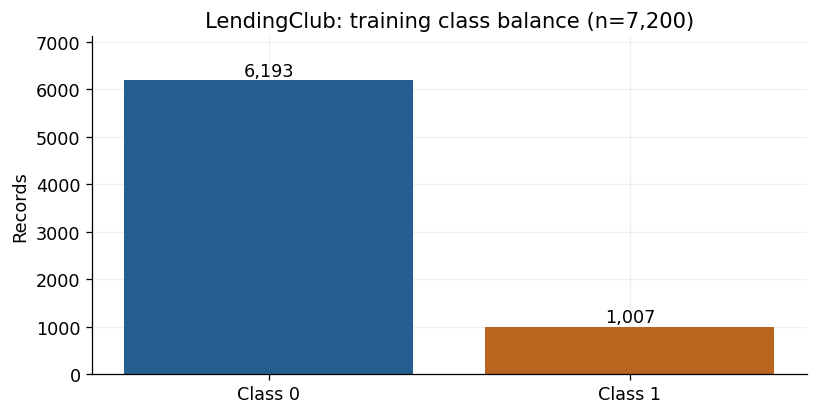

In [15]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### B3. Tune parameters inside training CV

In [16]:
# A compact grid is prespecified. Bank k must fit the smallest training fold.
k_values=[1,3,5,9] if groups is not None else [5,25,75,151]
assert max(k_values)<=min(len(a) for a,b in folds)
specifications={
    'Manhattan KNN':(KNeighborsClassifier(metric='minkowski',p=1,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']}),
    'Euclidean KNN':(KNeighborsClassifier(metric='minkowski',p=2,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=True)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:s.best_estimator_ for name,s in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,**s.best_params_} for name,s in searches.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. Training scores include each record itself among its neighbors; '
    'distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Manhattan KNN,0.6222,0.0205,1.0000,0.6251,0.1981,7.1489
Euclidean KNN,0.6306,0.0210,1.0000,0.6288,0.1975,3.5464


,Model,model__n_neighbors,model__weights
0,Manhattan KNN,151,distance
1,Euclidean KNN,151,distance


Validation selected **Euclidean KNN**. Training scores include each record itself among its neighbors; distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.

### B4. Inspect distance, k and vote weighting

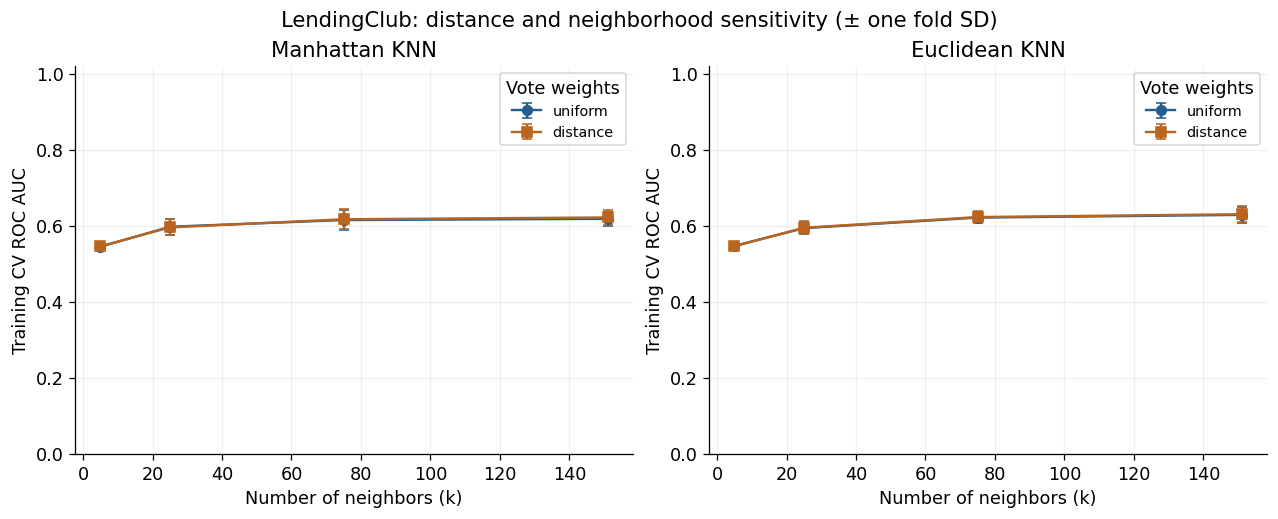

In [17]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout='constrained')
for ax,(name,search) in zip(axes,searches.items()):
    cv=pd.DataFrame(search.cv_results_)
    for weight,color,marker in [('uniform',BLUE,'o'),('distance',ORANGE,'s')]:
        part=cv[cv['param_model__weights'].eq(weight)].sort_values('param_model__n_neighbors')
        ax.errorbar(part['param_model__n_neighbors'].astype(int),part['mean_test_auc'],
            yerr=part['std_test_auc'],label=weight,color=color,marker=marker,capsize=3)
    ax.set(title=name,xlabel='Number of neighbors (k)',ylabel='Training CV ROC AUC',ylim=(0,1.02))
    ax.legend(title='Vote weights',fontsize=9)
fig.suptitle(f'{plot_label}: distance and neighborhood sensitivity (± one fold SD)')
plt.show()

### B5. Compare scaling with a fixed model

,Numeric scaling,Mean CV AUC,Fold SD,Fixed k
0,None,0.6080,0.0110,25
1,Standard,0.5941,0.0157,25


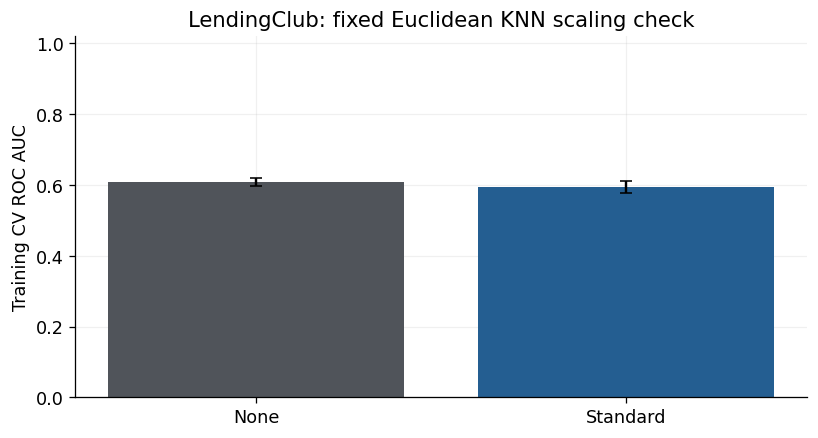

Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.

In [18]:
# Fixed k and equal votes isolate scaling; this does not replace the prespecified selection.
scale_k=5 if groups is not None else 25
scale_rows=[]
for scale in [False,True]:
    fixed=pipeline(KNeighborsClassifier(n_neighbors=scale_k,p=2,weights='uniform',algorithm='brute'),scale=scale)
    cv_scores=cross_val_score(fixed,X_train,y_train,cv=folds,scoring='roc_auc',n_jobs=1)
    scale_rows.append({'Numeric scaling':'Standard' if scale else 'None','Mean CV AUC':cv_scores.mean(),
        'Fold SD':cv_scores.std(ddof=0),'Fixed k':scale_k})
scale_table=pd.DataFrame(scale_rows)
display(scale_table)
fig,ax=plt.subplots(figsize=(7,3.7),layout='constrained')
ax.bar(scale_table['Numeric scaling'],scale_table['Mean CV AUC'],
    yerr=scale_table['Fold SD'],capsize=4,color=[GRAY,BLUE])
ax.set(ylim=(0,1.02),ylabel='Training CV ROC AUC',title=f'{plot_label}: fixed Euclidean KNN scaling check')
plt.show()
display(Markdown('Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, '
    'not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.'))

### B6. Inspect validation neighborhood distances

,Nearest distance,kth-neighbor distance,Nearest / kth
count,"2,400.0000","2,400.0000","2,400.0000"
mean,0.9787,2.2208,0.4306
min,0.2334,1.5297,0.1119
50%,0.8883,2.1641,0.4173
max,2.5788,4.8969,0.7652


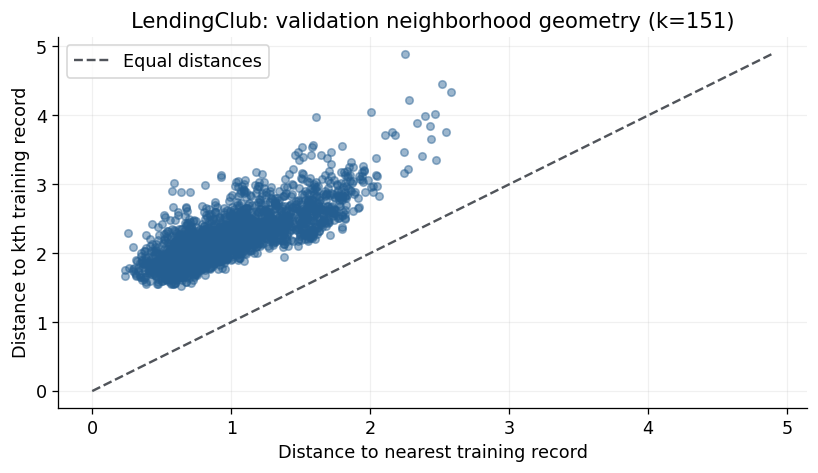

Transformed feature count: **25**. Median nearest/kth distance ratio: **0.417**; **0** validation rows have a zero-distance training neighbor. Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.

In [19]:
# Inspect validation-to-training distances without displaying customer or loan identifiers.
Z_valid=selected.named_steps['prepare'].transform(X_valid)
Z_train=selected.named_steps['prepare'].transform(X_train)
model=selected.named_steps['model']
distances,neighbors=model.kneighbors(Z_valid)
nearest=distances[:,0]; farthest=distances[:,-1]
ratio=np.divide(nearest,farthest,out=np.zeros_like(nearest),where=farthest>0)
display(pd.DataFrame({'Nearest distance':nearest,'kth-neighbor distance':farthest,
    'Nearest / kth':ratio}).describe().loc[['count','mean','min','50%','max']])
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.scatter(nearest,farthest,color=BLUE,alpha=.45,s=22,marker='o')
upper=max(float(farthest.max()),.01)
ax.plot([0,upper],[0,upper],color=GRAY,linestyle='--',label='Equal distances')
ax.set(xlabel='Distance to nearest training record',ylabel='Distance to kth training record',
    title=f'{plot_label}: validation neighborhood geometry (k={model.n_neighbors})')
ax.legend();plt.show()
display(Markdown(f'Transformed feature count: **{Z_train.shape[1]}**. Median nearest/kth distance ratio: '
    f'**{np.median(ratio):.3f}**; **{int((nearest==0).sum())}** validation rows have a zero-distance training neighbor. '
    'Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. '
    'Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6288,0.1975,0.8600,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.6288,0.1975,0.6625,0.5982,0.2096,0.5089,0.2969,816


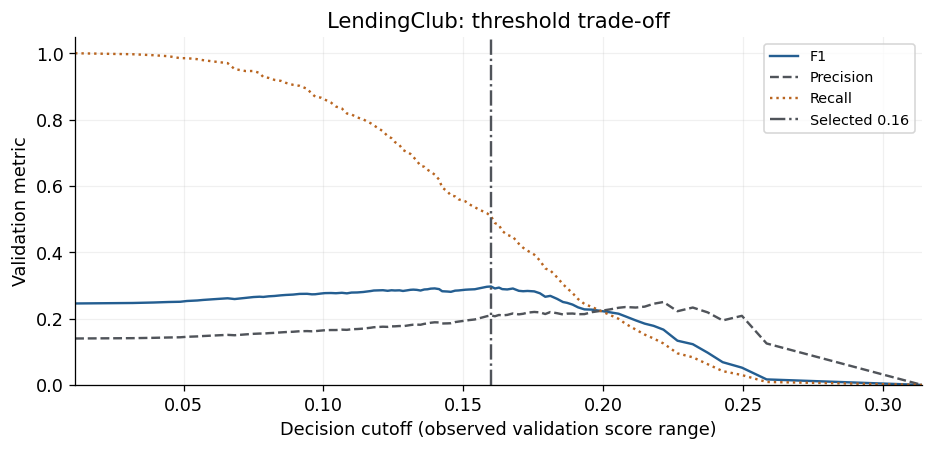

In [20]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [21]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Manhattan KNN,0.6186,0.2072,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.3954,0.1179
Euclidean KNN,0.6197,0.2098,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.3940,0.1176
Logistic baseline,0.6333,0.2087,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.3919,0.1173
Prevalence baseline,0.5000,0.1400,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.4050,0.1204
Euclidean KNN (validation F1 cutoff),0.6197,0.2098,0.6479,0.5735,0.1915,0.4702,0.2722,825,0.3940,0.1176


95% stratified row-bootstrap AUC interval: [0.585, 0.652]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

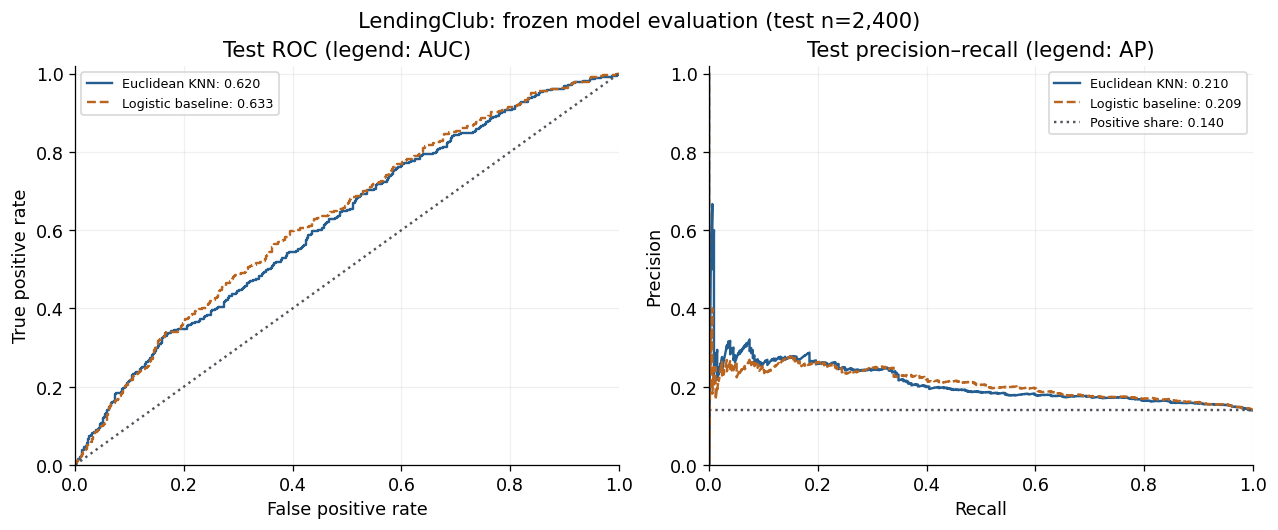

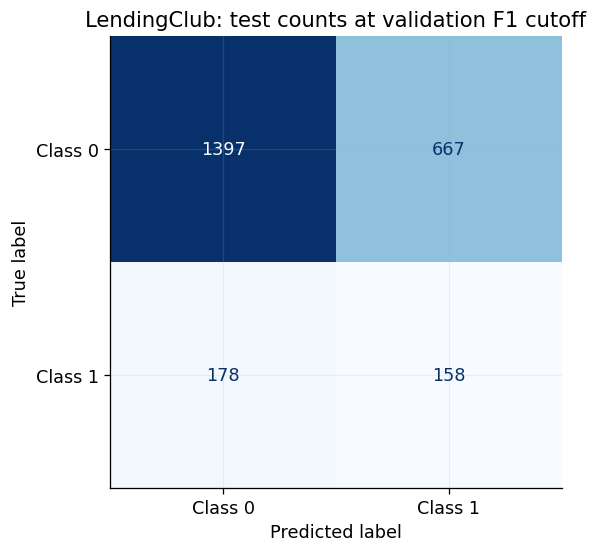

In [22]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [23]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — accepted_2007_to_2018Q4.csv

The prespecified selection gives **Euclidean KNN**, with test ROC AUC **0.620** and average precision **0.210** against test positive share **0.140**. Logistic baseline AUC is **0.633**; the descriptive AUC difference is **-0.014**, without a significance claim.

The validation-selected cutoff yields test F1 **0.272**, with TN=1397, FP=667, FN=178, TP=158. An always-positive rule on these test labels has F1 **0.246**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **0.394** versus **0.405** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.


**What this dataset teaches.** Both metrics chose distance voting and k=151, again at the upper search boundary. Euclidean validation AUC was 0.629 versus 0.625 for Manhattan. The separate fixed-k scaling check went in the opposite direction from Loan_Default: mean CV AUC fell from 0.608 without scaling to 0.594 with scaling. This does not replace the prespecified scaled selection. On test, KNN AUC 0.620 was below the matched logistic baseline 0.633, so locality did not establish a ranking improvement.

## C. bank_customers.csv — independent analysis

**Outcome:** checking=1 versus savings/CD=0, derived from AccountType. Use only age and historical tenure as predictors; exclude AccountType itself. This file supplies **no loan-default label**, so this is an account-type classification demonstration. Keep prior date eligibility rules and group repeated AccountID values conservatively. Read no SSNs and display no personal identifiers. Explicitly report the 100-row source audit and 39-row eligible population.

### C1. Load and reconcile source data

In [24]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,24,16,8,0.3333,21
Validation,7,5,2,0.2857,7
Test,8,2,6,0.7500,8


,Training missing (%)
age_years,0.0000
tenure_years,0.0000


,age_years,tenure_years
min,18.5736,1.3990
median,55.2005,23.3566
max,74.6667,64.1396


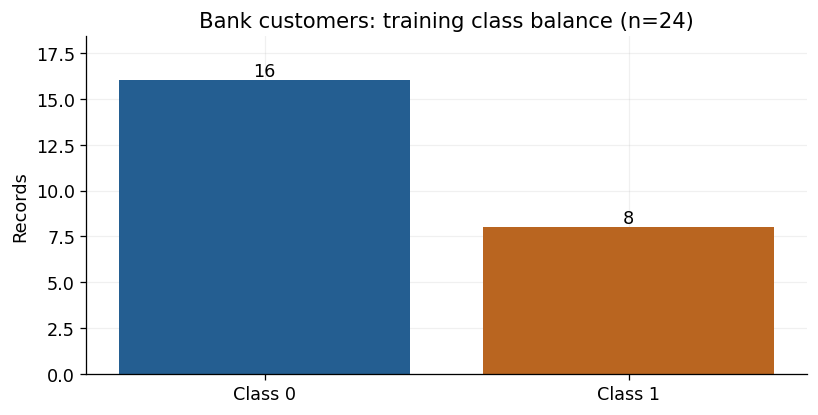

In [25]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### C3. Tune parameters inside training CV

In [26]:
# A compact grid is prespecified. Bank k must fit the smallest training fold.
k_values=[1,3,5,9] if groups is not None else [5,25,75,151]
assert max(k_values)<=min(len(a) for a,b in folds)
specifications={
    'Manhattan KNN':(KNeighborsClassifier(metric='minkowski',p=1,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']}),
    'Euclidean KNN':(KNeighborsClassifier(metric='minkowski',p=2,algorithm='brute',n_jobs=1),
        {'model__n_neighbors':k_values,'model__weights':['uniform','distance']})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=True)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:s.best_estimator_ for name,s in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,**s.best_params_} for name,s in searches.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. Training scores include each record itself among its neighbors; '
    'distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Manhattan KNN,0.5486,0.0354,1.0000,0.9000,0.8333,0.1141
Euclidean KNN,0.5139,0.0856,1.0000,0.4000,0.2857,0.1100


,Model,model__n_neighbors,model__weights
0,Manhattan KNN,9,distance
1,Euclidean KNN,1,uniform


Validation selected **Manhattan KNN**. Training scores include each record itself among its neighbors; distance-weighted training AUC can therefore be perfect. Held-out folds, validation and test are the relevant generalization evidence.

### C4. Inspect distance, k and vote weighting

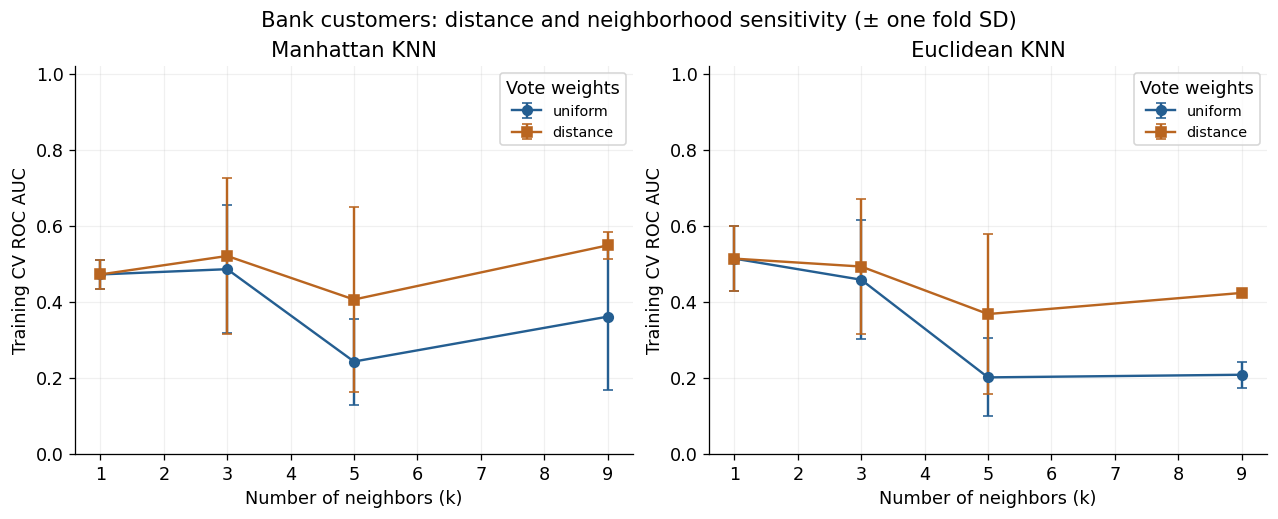

In [27]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout='constrained')
for ax,(name,search) in zip(axes,searches.items()):
    cv=pd.DataFrame(search.cv_results_)
    for weight,color,marker in [('uniform',BLUE,'o'),('distance',ORANGE,'s')]:
        part=cv[cv['param_model__weights'].eq(weight)].sort_values('param_model__n_neighbors')
        ax.errorbar(part['param_model__n_neighbors'].astype(int),part['mean_test_auc'],
            yerr=part['std_test_auc'],label=weight,color=color,marker=marker,capsize=3)
    ax.set(title=name,xlabel='Number of neighbors (k)',ylabel='Training CV ROC AUC',ylim=(0,1.02))
    ax.legend(title='Vote weights',fontsize=9)
fig.suptitle(f'{plot_label}: distance and neighborhood sensitivity (± one fold SD)')
plt.show()

### C5. Compare scaling with a fixed model

,Numeric scaling,Mean CV AUC,Fold SD,Fixed k
0,None,0.2014,0.1025,5
1,Standard,0.2014,0.1025,5


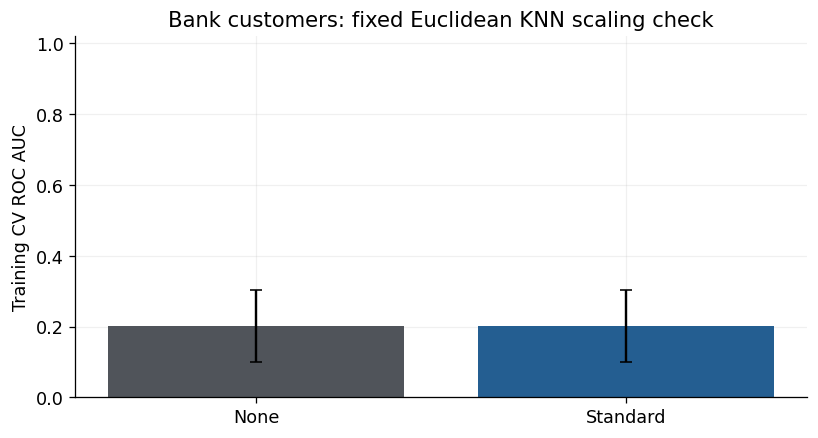

Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.

In [28]:
# Fixed k and equal votes isolate scaling; this does not replace the prespecified selection.
scale_k=5 if groups is not None else 25
scale_rows=[]
for scale in [False,True]:
    fixed=pipeline(KNeighborsClassifier(n_neighbors=scale_k,p=2,weights='uniform',algorithm='brute'),scale=scale)
    cv_scores=cross_val_score(fixed,X_train,y_train,cv=folds,scoring='roc_auc',n_jobs=1)
    scale_rows.append({'Numeric scaling':'Standard' if scale else 'None','Mean CV AUC':cv_scores.mean(),
        'Fold SD':cv_scores.std(ddof=0),'Fixed k':scale_k})
scale_table=pd.DataFrame(scale_rows)
display(scale_table)
fig,ax=plt.subplots(figsize=(7,3.7),layout='constrained')
ax.bar(scale_table['Numeric scaling'],scale_table['Mean CV AUC'],
    yerr=scale_table['Fold SD'],capsize=4,color=[GRAY,BLUE])
ax.set(ylim=(0,1.02),ylabel='Training CV ROC AUC',title=f'{plot_label}: fixed Euclidean KNN scaling check')
plt.show()
display(Markdown('Scaling changes numeric feature contributions to distance. This is a controlled training-CV comparison, '
    'not a claim that scaling must improve every dataset. One-hot category blocks are unchanged.'))

### C6. Inspect validation neighborhood distances

,Nearest distance,kth-neighbor distance,Nearest / kth
count,7.0000,7.0000,7.0000
mean,0.5283,1.8054,0.3002
min,0.1205,1.2117,0.0607
50%,0.4619,1.5342,0.2904
max,0.9581,3.2995,0.6062


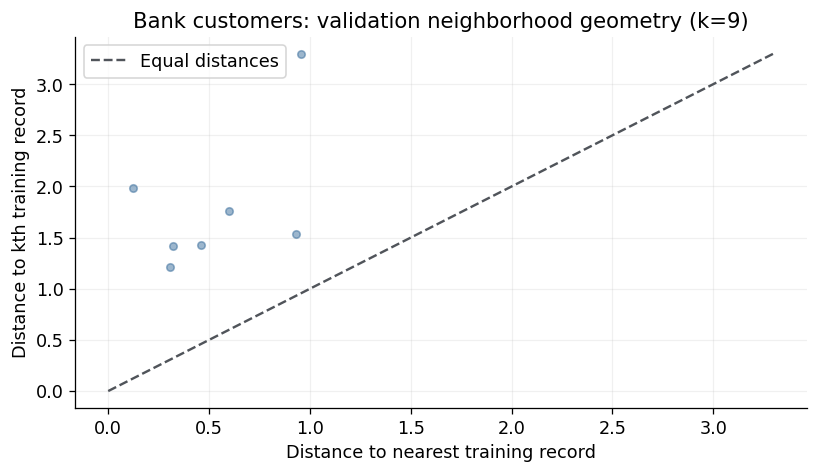

Transformed feature count: **2**. Median nearest/kth distance ratio: **0.290**; **0** validation rows have a zero-distance training neighbor. Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.

In [29]:
# Inspect validation-to-training distances without displaying customer or loan identifiers.
Z_valid=selected.named_steps['prepare'].transform(X_valid)
Z_train=selected.named_steps['prepare'].transform(X_train)
model=selected.named_steps['model']
distances,neighbors=model.kneighbors(Z_valid)
nearest=distances[:,0]; farthest=distances[:,-1]
ratio=np.divide(nearest,farthest,out=np.zeros_like(nearest),where=farthest>0)
display(pd.DataFrame({'Nearest distance':nearest,'kth-neighbor distance':farthest,
    'Nearest / kth':ratio}).describe().loc[['count','mean','min','50%','max']])
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.scatter(nearest,farthest,color=BLUE,alpha=.45,s=22,marker='o')
upper=max(float(farthest.max()),.01)
ax.plot([0,upper],[0,upper],color=GRAY,linestyle='--',label='Equal distances')
ax.set(xlabel='Distance to nearest training record',ylabel='Distance to kth training record',
    title=f'{plot_label}: validation neighborhood geometry (k={model.n_neighbors})')
ax.legend();plt.show()
display(Markdown(f'Transformed feature count: **{Z_train.shape[1]}**. Median nearest/kth distance ratio: '
    f'**{np.median(ratio):.3f}**; **{int((nearest==0).sum())}** validation rows have a zero-distance training neighbor. '
    'Zero distances can reflect identical encoded profiles and do not by themselves prove duplicate people. '
    'Ratios close to one indicate limited distance contrast within the chosen neighborhood, not a formal dimensionality test.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.9000,0.8333,0.8571,0.7500,1.0000,0.5000,0.6667,1
Validation F1,0.9000,0.8333,0.8571,0.9000,0.6667,1.0000,0.8000,3


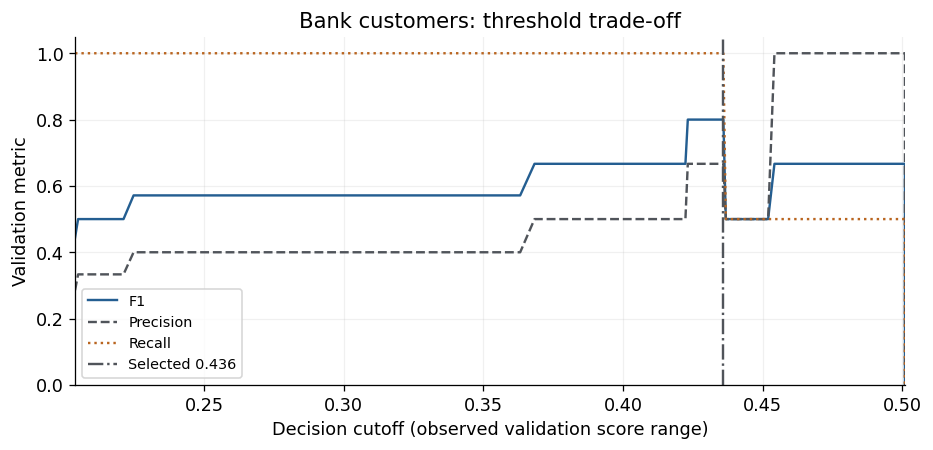

In [30]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [31]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Manhattan KNN,0.3333,0.7885,0.3750,0.4167,0.6667,0.3333,0.4444,3,0.9531,0.3641
Euclidean KNN,0.1667,0.6667,0.2500,0.1667,0.5000,0.3333,0.4000,4,27.0327,0.7500
Logistic baseline,0.5833,0.8179,0.2500,0.5000,0.0000,0.0000,0.0000,0,0.8913,0.3451
Prevalence baseline,0.5000,0.7500,0.2500,0.5000,0.0000,0.0000,0.0000,0,0.9253,0.3611
Manhattan KNN (validation F1 cutoff),0.3333,0.7885,0.3750,0.4167,0.6667,0.3333,0.4444,3,0.9531,0.3641


Bank test set: exact confusion counts are primary; no reliable population interval is claimed.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

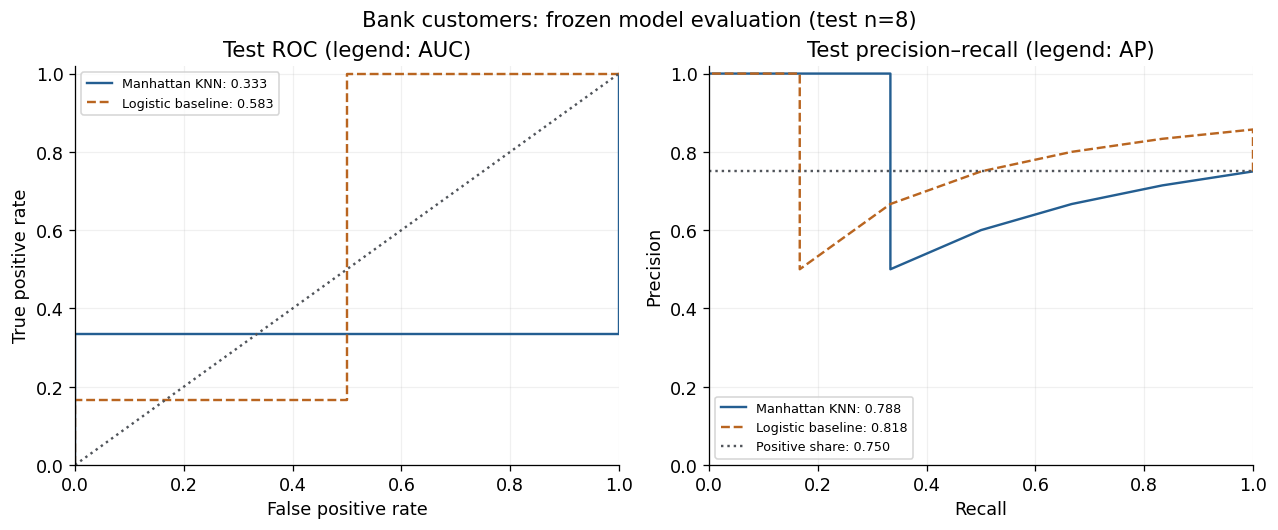

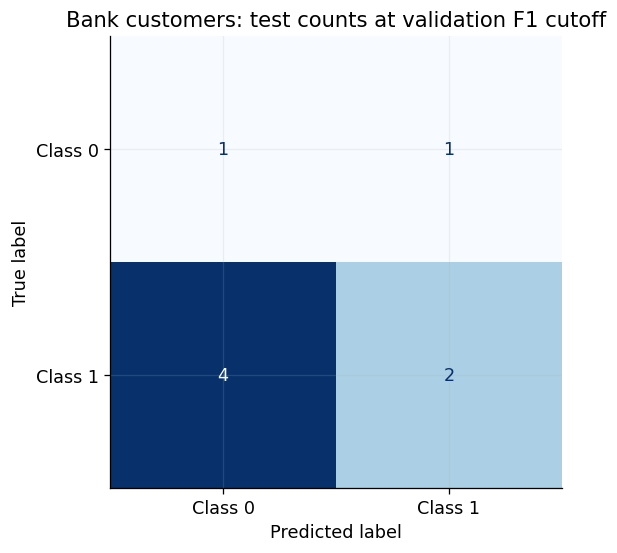

In [32]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [33]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — bank_customers.csv

The prespecified selection gives **Manhattan KNN**, with test ROC AUC **0.333** and average precision **0.788** against test positive share **0.750**. Logistic baseline AUC is **0.583**; the descriptive AUC difference is **-0.250**, without a significance claim.

The validation-selected cutoff yields test F1 **0.444**, with TN=1, FP=1, FN=4, TP=2. An always-positive rule on these test labels has F1 **0.857**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **0.953** versus **0.925** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.


**What this dataset teaches.** Training CV chose Manhattan k=9 with distance voting; its validation AUC was 0.900, but test AUC was 0.333. Euclidean CV instead chose k=1, and its validation AUC was 0.400. Large changes across distance choices and tiny partitions demonstrate instability. AP 0.788 must be read against 75% test prevalence, and selected-cutoff F1 0.444 is below the always-positive reference 0.857. These results do not support reliable account classification.

## Takeaways across all three datasets

Compare models within a dataset; targets and populations differ. The summary below is computed from this run.

In [34]:
all_results=pd.DataFrame(results).set_index('Dataset')
assert set(all_results.index)=={'Loan_Default.csv','accepted_2007_to_2018Q4.csv','bank_customers.csv'}
assert len(all_results)==3
display(all_results)
for row in results:
    display(Markdown(f"- **{row['Dataset']}** — {row['Outcome']}: **{row['Selected']}**, test AUC **{row['ROC AUC']:.3f}**, AP **{row['Average precision']:.3f}**, F1 at the validation cutoff **{row['F1 (validation cutoff)']:.3f}**, test n={row['Test n']:,}."))

,Outcome,Selected,Train n,Validation n,Test n,ROC AUC,Average precision,Test positive share,F1 (validation cutoff),Cutoff,Logistic AUC,Always-positive F1
Dataset,,,,,,,,,,,,
Loan_Default.csv,recorded Status 1,Euclidean KNN,7200,2400,2400,0.6092,0.3343,0.2367,0.3992,0.1863,0.5906,0.3827
accepted_2007_to_2018Q4.csv,charged off among resolved 2015 36-month loans,Euclidean KNN,7200,2400,2400,0.6197,0.2098,0.1400,0.2722,0.1599,0.6333,0.2456
bank_customers.csv,checking account versus savings/CD,Manhattan KNN,24,7,8,0.3333,0.7885,0.7500,0.4444,0.4359,0.5833,0.8571


- **Loan_Default.csv** — recorded Status 1: **Euclidean KNN**, test AUC **0.609**, AP **0.334**, F1 at the validation cutoff **0.399**, test n=2,400.

- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Euclidean KNN**, test AUC **0.620**, AP **0.210**, F1 at the validation cutoff **0.272**, test n=2,400.

- **bank_customers.csv** — checking account versus savings/CD: **Manhattan KNN**, test AUC **0.333**, AP **0.788**, F1 at the validation cutoff **0.444**, test n=8.

## Milestone Two synthesis and limitations

Use the CV distance/k curves, fixed-k scaling experiment and validation-distance diagnostic to explain why neighborhood geometry matters. Distance-weighted training accuracy is especially optimistic because training points can be their own nearest neighbor. High test AP should be compared with test prevalence.

Preserve the cohort definitions, sampling audits, frozen cutoff, test counts and limitations when preparing Milestone Two. A historical random split does not establish future-cohort performance. Loan_Default needs documented status timing; LendingClub conditions on resolved outcomes; the bank study needs substantially more valid records and a decision-relevant target. Verify feature availability at prediction time and borrower identity, use future-vintage evaluation, and specify decision costs before considering operational use. No causal, fairness or deployment conclusion is supported.

The Milestone Two rubric/link was absent, so rubric-specific coverage cannot be verified.

## Sources and reproducibility

**Data:** the three original local CSVs in `DATA/`; source counts, filters, excluded outcomes, date eligibility and sample sizes are printed above. No external observations were added. The bank reference date remains 2026-09-26 solely to preserve comparisons.

**Method reference:** [scikit-learn nearest-neighbor guide](https://scikit-learn.org/stable/modules/neighbors.html) (consulted October 25, 2026). The printed execution environment identifies the installed version; documentation may describe a later release.

Rerun with `python3 -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1200 "Week 8.ipynb"` from the repository. Static summaries describe the delivered run; revise them if inputs or settings change.